# Predicción de la posición habitual de un jugador de fútbol
## 01 · Auditoría y limpieza de datos

Proyecto final de Sistemas Inteligentes · UNAM · Matemáticas Aplicadas y Computación

## Objetivo

Partir de las respuestas originales del formulario y dejar una base **limpia, anónima y documentada**, lista para el análisis exploratorio y el modelado. Es el paso de *limpieza y preparación* de la estructura que pidió la maestra.

## Cómo se hace la limpieza

- **Solo Python con reglas explícitas y expresiones regulares.** No se usa IA ni NLP, y no se edita nada a mano en Excel o CSV.
- **No se elimina información para mejorar resultados.** Los duplicados posibles, las edades atípicas, las respuestas "en línea recta" y otros casos dudosos **se marcan con una bandera**; no se borran. Más adelante se prueba el modelo con y sin ellos.
- **La única exclusión es por regla del formulario:** quien respondió "No" a la pregunta 1 (no ha jugado fútbol ni puede identificar su posición) no tiene variable objetivo.
- **Se conserva la respuesta original** en un archivo aparte (sin marca temporal).
- **Cada paso queda en una bitácora** con el número de filas que afectó.

## Qué población representan los datos

La pregunta 1 solo pide haber jugado fútbol **en cualquier nivel** (escolar, recreativo, amateur, competitivo o profesional), no únicamente profesionales. Se hizo así para poder reunir más respuestas. Por eso la muestra está formada sobre todo por personas que juegan por diversión, y esto es una **limitación** que debe decirse en los documentos: el modelo aprende cómo se describen **jugadores en su mayoría recreativos** y no futbolistas profesionales.

## Archivos

| Entrada | Salida |
|---|---|
| El CSV que se descarga de Google Forms | `Datos_Limpios.csv` (base para EDA y modelos) |
| | `Respuestas_Originales_Anonimas.csv` (texto original, sin marca temporal) |
| | `Bitacora_Limpieza.csv` (cada paso de la limpieza) |

**Privacidad:** el formulario no pide nombres ni contacto. Aun así, la **marca temporal se elimina** y cada persona queda con un código (`P001`, `P002`...).

### Preparar el entorno
*Qué hace:* importa las herramientas y revisa si estamos en Google Colab. Muestra las versiones para dejarlas documentadas.

In [ ]:
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from google.colab import files  # solo existe dentro de Google Colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

try:
    from IPython.display import display
except ImportError:
    display = print

print("pandas", pd.__version__, "| numpy", np.__version__, "| Colab:", EN_COLAB)

pandas 2.2.3 | numpy 2.4.6 | Colab: True


### Cargar las respuestas
*Qué hace:* busca el archivo CSV que se descargó de Google Forms (si no está, en Colab abre una ventana para subirlo) y lo lee tal cual, sin modificar nada.

In [ ]:
ARCHIVO = "Predicción de la posición habitual de un jugador de fútbol.csv"


def buscar_archivo():
    if os.path.exists(ARCHIVO):
        return ARCHIVO
    # Por si el nombre cambió un poco al descargarlo o subirlo.
    otros = [f for f in os.listdir(".") if f.lower().endswith(".csv") and "jugador" in f.lower()]
    return otros[0] if len(otros) == 1 else None


ruta = buscar_archivo()
if ruta is None and EN_COLAB:
    print("Elige el CSV de respuestas en la ventana que se abre...")
    files.upload()
    ruta = buscar_archivo()
if ruta is None:
    raise FileNotFoundError(
        f"No se encontró '{ARCHIVO}'. Súbelo al panel de archivos de Colab con ese nombre."
    )

crudo = pd.read_csv(ruta, encoding="utf-8")
print("Archivo:", ruta)
print(f"Filas recibidas: {crudo.shape[0]} | Columnas: {crudo.shape[1]}")

Elige el CSV de respuestas en la ventana que se abre...


Saving Predicción de la posición habitual de un jugador de fútbol.csv to Predicción de la posición habitual de un jugador de fútbol.csv
Archivo: Predicción de la posición habitual de un jugador de fútbol.csv
Filas recibidas: 290 | Columnas: 19


## 1. Estructura del formulario

### Nombres de columnas
*Qué hace:* cada columna de Google Forms trae la pregunta completa como nombre. Con una **expresión regular** tomamos el número de la pregunta (`"7. ¿Cómo calificarías..."` → 7) y le damos un nombre corto. Se comprueba que estén las 18 preguntas, una sola vez cada una, para detectar si el formulario cambió.

In [ ]:
bitacora = []


def registrar(paso, descripcion, filas):
    bitacora.append({
        "n": len(bitacora) + 1,
        "paso": paso,
        "descripcion": descripcion,
        "filas_afectadas": int(filas),
    })


NOMBRES = {
    1: "jugo", 2: "edad", 3: "tiempo_juego", 4: "horas_semana", 5: "nivel", 6: "posicion",
    7: "velocidad", 8: "resistencia", 9: "fuerza", 10: "control_balon", 11: "regate",
    12: "pase", 13: "definicion", 14: "defensa", 15: "juego_aereo", 16: "vision_juego",
    17: "reflejos", 18: "posicionamiento",
}
HABILIDADES = list(NOMBRES.values())[6:]  # preguntas 7 a 18

renombres = {crudo.columns[0]: "marca_temporal"}
for columna in crudo.columns[1:]:
    coincidencia = re.match(r"^\s*(\d+)\.", columna)
    if coincidencia is None:
        raise ValueError(f"La columna no empieza con un número de pregunta: {columna!r}")
    renombres[columna] = NOMBRES[int(coincidencia.group(1))]

if sorted(renombres.values()) != sorted(["marca_temporal"] + list(NOMBRES.values())):
    raise ValueError("Las preguntas del archivo no coinciden con las 18 esperadas.")

df = crudo.rename(columns=renombres)
registrar("Estructura", "Se renombraron las 19 columnas (marca temporal + 18 preguntas) con una expresión regular sobre el número de pregunta.", len(df))
print("Columnas:", list(df.columns))

Columnas: ['marca_temporal', 'jugo', 'edad', 'tiempo_juego', 'horas_semana', 'nivel', 'posicion', 'velocidad', 'resistencia', 'fuerza', 'control_balon', 'regate', 'pase', 'definicion', 'defensa', 'juego_aereo', 'vision_juego', 'reflejos', 'posicionamiento']


### Marca temporal: solo para ordenar
*Qué hace:* convierte la marca temporal (por ejemplo `2026/11/19 5:03:20 p. m. GMT-6`) en fecha y hora con una expresión regular, ordena las respuestas por orden de llegada y guarda una **copia del texto original** de cada respuesta. La marca temporal se usa únicamente para ordenar y **no pasa a los archivos de salida**.

In [ ]:
PATRON_FECHA = r"(\d{4})/(\d{2})/(\d{2}) (\d{1,2}):(\d{2}):(\d{2})\s*([ap])"
partes = df["marca_temporal"].str.extract(PATRON_FECHA)
if partes.isna().any().any():
    raise ValueError("Hay marcas temporales con un formato que no se reconoce.")

hora24 = partes[3].astype(int) % 12 + 12 * (partes[6].str.lower() == "p").astype(int)
df["_fecha_hora"] = pd.to_datetime(
    partes[0] + "-" + partes[1] + "-" + partes[2] + " " + hora24.astype(str) + ":" + partes[4] + ":" + partes[5],
    format="%Y-%m-%d %H:%M:%S",
)
df = df.sort_values("_fecha_hora", kind="stable").reset_index(drop=True)

# Copia del texto tal como llegó (se guarda aparte, sin marca temporal).
original = df.drop(columns=["marca_temporal", "_fecha_hora"]).copy()

print("Primera respuesta:", df["_fecha_hora"].min(), "| Última:", df["_fecha_hora"].max())
registrar("Orden", "Se ordenaron las respuestas por orden de llegada. La marca temporal no se incluye en los archivos de salida.", len(df))

Primera respuesta: 2026-10-29 08:00:08 | Última: 2026-11-20 18:41:09


## 2. Normalizar las categorías con expresiones regulares

*Qué hace:* cada pregunta de opción cerrada solo debería tener ciertos valores. Con una **regla (expresión regular) por valor permitido** reconocemos cada respuesta aunque tenga espacios de más o diferencias de mayúsculas, y la dejamos escrita siempre igual. Si aparece algún valor que **ninguna regla reconoce**, el cuaderno se detiene y avisa, en lugar de adivinar.

In [ ]:
REGLAS = {
    "jugo": [
        (r"^s[ií]\b", "Sí"),
        (r"^no\b", "No"),
    ],
    "tiempo_juego": [
        (r"^menos de 1", "Menos de 1 año"),
        (r"^de 1 a 2", "De 1 a 2 años"),
        (r"^de 3 a 5", "De 3 a 5 años"),
        (r"^de 6 a 10", "De 6 a 10 años"),
        (r"^m[aá]s de 10", "Más de 10 años"),
    ],
    "horas_semana": [
        (r"^(actualmente,? )?ninguna", "Actualmente, ninguna"),
        (r"^de 1 a 2", "De 1 a 2 horas"),
        (r"^de 3 a 5", "De 3 a 5 horas"),
        (r"^de 6 a 8", "De 6 a 8 horas"),
        (r"^de 9 a 12", "De 9 a 12 horas"),
        (r"^m[aá]s de 12", "Más de 12 horas"),
    ],
    "nivel": [
        (r"^escolar", "Escolar"),
        (r"^recreativo", "Recreativo (por diversión)"),
        (r"^amateur", "Amateur en un equipo organizado"),
        (r"^competitivo", "Competitivo o semiprofesional"),
        (r"^profesional", "Profesional"),
    ],
    "posicion": [
        (r"^portero", "Portero"),
        (r"^defensa central", "Defensa central"),
        (r"^lateral", "Lateral"),
        (r"^mediocampista defensivo", "Mediocampista defensivo"),
        (r"^mediocampista ofensivo", "Mediocampista ofensivo"),
        (r"^extremo", "Extremo"),
        (r"^delantero", "Delantero"),
    ],
}


def normalizar(serie, reglas):
    resultado = []
    for valor in serie:
        if pd.isna(valor):
            resultado.append(np.nan)
            continue
        limpio = re.sub(r"\s+", " ", str(valor)).strip()  # espacios de más
        for patron, canonico in reglas:
            if re.match(patron, limpio, flags=re.IGNORECASE):
                resultado.append(canonico)
                break
        else:
            resultado.append("__SIN_REGLA__")
    return pd.Series(resultado, index=serie.index, dtype=object)


for columna, reglas in REGLAS.items():
    nueva = normalizar(df[columna], reglas)
    sin_regla = nueva == "__SIN_REGLA__"
    if sin_regla.any():
        raise ValueError(f"Valores sin regla en '{columna}': {df.loc[sin_regla, columna].unique().tolist()}")
    cambiaron = int(((nueva != df[columna]) & df[columna].notna()).sum())
    df[columna] = nueva
    registrar("Normalización", f"'{columna}': cada valor se reconoció con una regla; se reescribieron {cambiaron} respuestas.", cambiaron)
    print(f"{columna}: valores únicos = {sorted(nueva.dropna().unique().tolist())} | reescritas: {cambiaron}")

jugo: valores únicos = ['No', 'Sí'] | reescritas: 0
tiempo_juego: valores únicos = ['De 1 a 2 años', 'De 3 a 5 años', 'De 6 a 10 años', 'Menos de 1 año', 'Más de 10 años'] | reescritas: 0
horas_semana: valores únicos = ['Actualmente, ninguna', 'De 1 a 2 horas', 'De 3 a 5 horas', 'De 6 a 8 horas', 'De 9 a 12 horas', 'Más de 12 horas'] | reescritas: 0
nivel: valores únicos = ['Amateur en un equipo organizado', 'Competitivo o semiprofesional', 'Escolar', 'Profesional', 'Recreativo (por diversión)'] | reescritas: 0
posicion: valores únicos = ['Defensa central', 'Delantero', 'Extremo', 'Lateral', 'Mediocampista defensivo', 'Mediocampista ofensivo', 'Portero'] | reescritas: 0


## 3. Quién entra al análisis

*Qué hace:* la pregunta 1 pregunta si la persona ha jugado fútbol y puede identificar su posición. Quien respondió **"No"** no tiene variable objetivo, así que no puede entrar al modelo. Antes de apartar esas respuestas comprobamos que realmente estén vacías en todas las demás preguntas.

In [ ]:
es_no = df["jugo"] == "No"
columnas_resto = [c for c in df.columns if c not in ("marca_temporal", "_fecha_hora", "jugo")]
resto_vacio = df.loc[es_no, columnas_resto].isna().all().all()
print("Respuestas 'No':", int(es_no.sum()), "| ¿todas vacías en las demás preguntas?", bool(resto_vacio))
if not resto_vacio:
    raise ValueError("Hay respuestas 'No' que sí contestaron otras preguntas: revisar antes de excluirlas.")

registrar("Exclusión por regla", "Se apartaron las respuestas que dijeron 'No' a la pregunta 1 (sin posición, y vacías en el resto).", es_no.sum())

mantener = ~es_no
datos = df[mantener].reset_index(drop=True)
original = original[mantener].reset_index(drop=True)
print("Respuestas que pasan al análisis:", len(datos))

Respuestas 'No': 18 | ¿todas vacías en las demás preguntas? True
Respuestas que pasan al análisis: 272


## 4. Tipos de datos y escalas

### Edad
*Qué hace:* la edad debe ser un número entero. Se revisa que esté en un rango razonable (5 a 100 años) y que no falte.

In [ ]:
datos["edad"] = pd.to_numeric(datos["edad"], errors="raise")
assert datos["edad"].notna().all(), "Hay edades vacías."
assert datos["edad"].between(5, 100).all(), "Hay edades fuera del rango 5-100."
datos["edad"] = datos["edad"].astype(int)
registrar("Tipos", "La edad se convirtió a entero y se verificó que estuviera entre 5 y 100 años.", len(datos))
print(datos["edad"].describe().round(1).to_string())

count    272.0
mean      31.2
std       13.0
min       13.0
25%       20.0
50%       27.0
75%       42.0
max       90.0


### Habilidades (preguntas 7 a 18)
*Qué hace:* cada habilidad llega como texto (`"4 — Alto/a"`). Con una expresión regular se extrae el número (1 a 5). La opción **"No sé / No puedo evaluarlo"** no es una calificación, así que se convierte en dato **faltante** y se cuenta por persona. **No se rellena ahora:** si se rellena, se hará más adelante dentro de la validación, para no contaminar los resultados.

In [ ]:
def convertir_escala(serie):
    es_no_se = serie.str.contains(r"^\s*no s[eé]", case=False, regex=True, na=False)
    numero = pd.to_numeric(serie.str.extract(r"^\s*([1-5])\s*[—–-]")[0])
    reconocida = numero.notna() | es_no_se
    if not reconocida.all():
        raise ValueError(f"Respuestas no reconocidas en la escala: {serie[~reconocida].unique().tolist()}")
    return numero, es_no_se


no_se = pd.DataFrame(index=datos.index)
for habilidad in HABILIDADES:
    numero, es_no_se = convertir_escala(datos[habilidad])
    datos[habilidad] = numero.astype("Int64")
    no_se[habilidad] = es_no_se

datos["n_no_se"] = no_se.sum(axis=1).astype(int)
total_celdas = int(no_se.to_numpy().sum())
personas_no_se = int((datos["n_no_se"] > 0).sum())
registrar("Escalas", f"Se extrajo el número (1-5) de las 12 habilidades con una expresión regular. 'No sé' pasó a faltante: {total_celdas} celdas.", total_celdas)
print(f"Respuestas 'No sé': {total_celdas} celdas, en {personas_no_se} personas")
print("Faltantes por habilidad:")
print(datos[HABILIDADES].isna().sum().to_string())

Respuestas 'No sé': 17 celdas, en 5 personas
Faltantes por habilidad:
velocidad          2
resistencia        1
fuerza             1
control_balon      2
regate             3
pase               1
definicion         1
defensa            1
juego_aereo        1
vision_juego       2
reflejos           1
posicionamiento    1


### Variables ordinales
*Qué hace:* `tiempo_juego` y `horas_semana` tienen un orden natural (más tiempo = más). Les damos un código numérico que respeta ese orden. El nivel (`nivel`) y la posición se dejan como categorías: se codifican en el modelado, dentro de la tubería.

In [ ]:
ORDEN_TIEMPO = ["Menos de 1 año", "De 1 a 2 años", "De 3 a 5 años", "De 6 a 10 años", "Más de 10 años"]
ORDEN_HORAS = ["Actualmente, ninguna", "De 1 a 2 horas", "De 3 a 5 horas", "De 6 a 8 horas", "De 9 a 12 horas", "Más de 12 horas"]

datos["tiempo_codigo"] = datos["tiempo_juego"].map({v: i for i, v in enumerate(ORDEN_TIEMPO)}).astype(int)
datos["horas_codigo"] = datos["horas_semana"].map({v: i for i, v in enumerate(ORDEN_HORAS)}).astype(int)
registrar("Codificación", "tiempo_juego (0-4) y horas_semana (0-5) se codificaron respetando su orden.", len(datos))
display(datos[["tiempo_juego", "tiempo_codigo", "horas_semana", "horas_codigo"]].drop_duplicates().sort_values(["tiempo_codigo", "horas_codigo"]).head(8))

,tiempo_juego,tiempo_codigo,horas_semana,horas_codigo
1,Menos de 1 año,0,"Actualmente, ninguna",0
2,Menos de 1 año,0,De 1 a 2 horas,1
252,Menos de 1 año,0,De 3 a 5 horas,2
13,De 1 a 2 años,1,"Actualmente, ninguna",0
23,De 1 a 2 años,1,De 1 a 2 horas,1
39,De 1 a 2 años,1,De 3 a 5 horas,2
12,De 3 a 5 años,2,"Actualmente, ninguna",0
18,De 3 a 5 años,2,De 1 a 2 horas,1


## 5. Señales de calidad (se marcan, no se borran)

Cada señal se guarda como una columna 0/1. Después se decide con justificación qué hacer con ellas; por ejemplo, entrenar los modelos con y sin los casos marcados y comparar.

| Bandera | Qué marca |
|---|---|
| `duplicado_posible` | Respuestas **idénticas en las 18 preguntas** a otra (puede ser una persona que contestó dos veces, o coincidencia) |
| `duplicado_repetida` | La segunda (o posterior) de esas respuestas idénticas |
| `menor_18` | Menos de 18 años |
| `edad_atipica` | Edad fuera del rango normal según la regla del rango intercuartílico (Q1 − 1.5·IQR a Q3 + 1.5·IQR) |
| `linea_recta` | Las habilidades tienen el mismo valor en todas (al menos 8 respondidas): suele indicar poca atención |
| `incoherencia_experiencia` | La edad no cuadra con el tiempo jugando (menos de 3 años entre el inicio mínimo del rango y la edad actual) |

In [ ]:
CLAVE_DUPLICADO = ["edad", "tiempo_juego", "horas_semana", "nivel", "posicion"] + HABILIDADES

datos["duplicado_posible"] = datos.duplicated(subset=CLAVE_DUPLICADO, keep=False).astype(int)
datos["duplicado_repetida"] = datos.duplicated(subset=CLAVE_DUPLICADO, keep="first").astype(int)

datos["menor_18"] = (datos["edad"] < 18).astype(int)

q1, q3 = datos["edad"].quantile(0.25), datos["edad"].quantile(0.75)
iqr = q3 - q1
limite_bajo, limite_alto = q1 - 1.5 * iqr, q3 + 1.5 * iqr
datos["edad_atipica"] = ((datos["edad"] < limite_bajo) | (datos["edad"] > limite_alto)).astype(int)

respondidas = datos[HABILIDADES].notna().sum(axis=1)
datos["linea_recta"] = ((datos[HABILIDADES].nunique(axis=1) == 1) & (respondidas >= 8)).astype(int)

ANIOS_MINIMOS = {"Menos de 1 año": 0, "De 1 a 2 años": 1, "De 3 a 5 años": 3, "De 6 a 10 años": 6, "Más de 10 años": 11}
anios_minimos = datos["tiempo_juego"].map(ANIOS_MINIMOS)
datos["incoherencia_experiencia"] = ((datos["edad"] - anios_minimos) < 3).astype(int)

BANDERAS = ["duplicado_posible", "duplicado_repetida", "menor_18", "edad_atipica", "linea_recta", "incoherencia_experiencia"]
descripciones = {
    "duplicado_posible": "respuestas idénticas en las 18 preguntas (grupo completo)",
    "duplicado_repetida": "segunda o posterior respuesta idéntica",
    "menor_18": "menores de 18 años",
    "edad_atipica": f"edad fuera de [{limite_bajo:.1f}, {limite_alto:.1f}] años",
    "linea_recta": "mismo valor en todas las habilidades",
    "incoherencia_experiencia": "edad incompatible con el tiempo jugando",
}
for bandera in BANDERAS:
    registrar("Bandera", f"'{bandera}': {descripciones[bandera]}. Solo se marca, no se elimina.", datos[bandera].sum())

resumen_banderas = pd.DataFrame({
    "bandera": BANDERAS,
    "personas": [int(datos[b].sum()) for b in BANDERAS],
    "descripcion": [descripciones[b] for b in BANDERAS],
})
display(resumen_banderas)

,bandera,personas,descripcion
0,duplicado_posible,14,respuestas idénticas en las 18 preguntas (grup...
1,duplicado_repetida,7,segunda o posterior respuesta idéntica
2,menor_18,33,menores de 18 años
3,edad_atipica,1,"edad fuera de [-13.0, 75.0] años"
4,linea_recta,4,mismo valor en todas las habilidades
5,incoherencia_experiencia,0,edad incompatible con el tiempo jugando


### Casos marcados para revisar
*Qué hace:* muestra los duplicados posibles y las edades atípicas, para que el equipo los vea y decida. Aquí **no se borra nada**.

In [ ]:
vistos = datos[(datos["duplicado_posible"] == 1) | (datos["edad_atipica"] == 1) | (datos["linea_recta"] == 1)]
columnas_vista = ["edad", "tiempo_juego", "nivel", "posicion"] + BANDERAS
display(vistos[columnas_vista].sort_values(["edad", "posicion"]))

,edad,tiempo_juego,nivel,posicion,duplicado_posible,duplicado_repetida,menor_18,edad_atipica,linea_recta,incoherencia_experiencia
80,16,Menos de 1 año,Recreativo (por diversión),Delantero,1,0,1,0,0,0
99,16,Menos de 1 año,Recreativo (por diversión),Delantero,1,1,1,0,0,0
184,16,De 1 a 2 años,Escolar,Extremo,1,0,1,0,0,0
212,16,De 1 a 2 años,Escolar,Extremo,1,1,1,0,0,0
1,18,Menos de 1 año,Recreativo (por diversión),Portero,0,0,0,0,1,0
86,22,De 1 a 2 años,Recreativo (por diversión),Mediocampista defensivo,1,0,0,0,0,0
101,22,De 1 a 2 años,Recreativo (por diversión),Mediocampista defensivo,1,1,0,0,0,0
106,27,De 3 a 5 años,Escolar,Lateral,1,0,0,0,0,0
156,27,De 3 a 5 años,Escolar,Lateral,1,1,0,0,0,0
112,30,De 3 a 5 años,Amateur en un equipo organizado,Mediocampista defensivo,1,0,0,0,0,0


## 6. Anonimizar y comprobar

*Qué hace:* asigna a cada persona un código (`P001`, `P002`...) por orden de llegada, verifica que no queden columnas de marca temporal y comprueba que los datos tengan sentido: siete posiciones válidas, sin vacíos fuera de las habilidades "No sé", y las habilidades solo entre 1 y 5.

In [ ]:
codigos = [f"P{i:03d}" for i in range(1, len(datos) + 1)]
datos.insert(0, "id_persona", codigos)
original.insert(0, "id_persona", codigos)

ORDEN_COLUMNAS = (
    ["id_persona", "edad", "tiempo_juego", "tiempo_codigo", "horas_semana", "horas_codigo", "nivel", "posicion"]
    + HABILIDADES + ["n_no_se"] + BANDERAS
)
limpios = datos[ORDEN_COLUMNAS].copy()

# Comprobaciones
assert limpios["id_persona"].is_unique
assert not any("marca" in c or "fecha" in c for c in limpios.columns), "Quedó una columna de fecha."
assert limpios["posicion"].isin([p for _, p in REGLAS["posicion"]]).all()
assert limpios["posicion"].nunique() == 7, "No están las siete posiciones."
assert limpios[["edad", "tiempo_juego", "horas_semana", "nivel", "posicion"]].notna().all().all()
for habilidad in HABILIDADES:
    valores = limpios[habilidad].dropna()
    assert valores.between(1, 5).all(), f"Valor fuera de 1-5 en {habilidad}"
assert len(limpios) == len(original) == int((~es_no).sum())

registrar("Anonimización", "Se asignó un código por persona (P001...) y se verificó que no haya marca temporal en los archivos de salida.", len(limpios))
print("Comprobaciones: OK")
print(f"Base limpia: {limpios.shape[0]} personas x {limpios.shape[1]} columnas")

Comprobaciones: OK
Base limpia: 272 personas x 27 columnas


## 7. Cómo quedó la variable objetivo

*Qué hace:* cuenta cuántas personas hay en cada posición (esto es **la variable que vamos a predecir**) y la edad de la muestra. Con el conteo se ve si alguna posición tiene muy pocos casos.

,personas,porcentaje
posicion,,
Defensa central,53,19.5
Delantero,43,15.8
Lateral,41,15.1
Mediocampista defensivo,39,14.3
Mediocampista ofensivo,37,13.6
Portero,32,11.8
Extremo,27,9.9


Azar entre 7 posiciones: 14.3 %
Modelo base (siempre 'Defensa central'): 19.5 %
Posición con menos casos: Extremo (27)


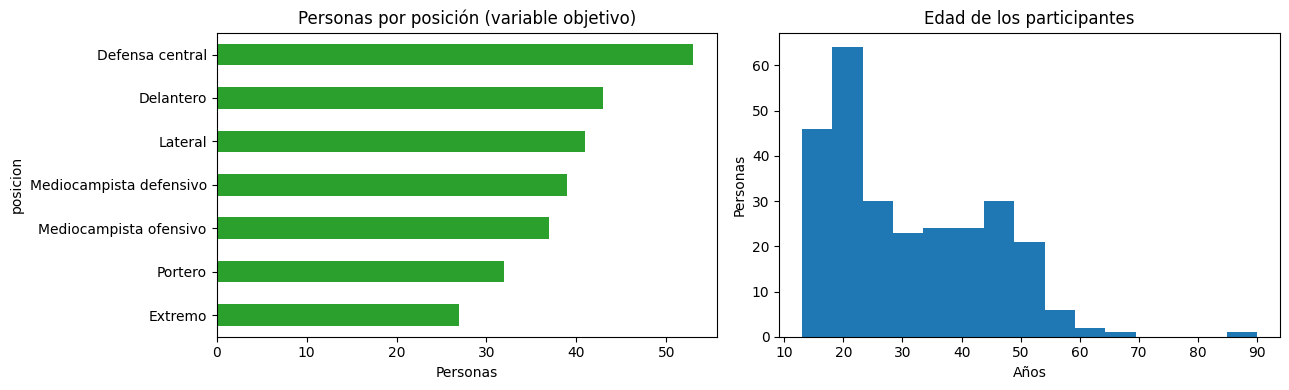

In [ ]:
conteo = limpios["posicion"].value_counts()
tabla = conteo.to_frame("personas")
tabla["porcentaje"] = (conteo / conteo.sum() * 100).round(1)
display(tabla)

total = int(conteo.sum())
print(f"Azar entre {len(conteo)} posiciones: {100 / len(conteo):.1f} %")
print(f"Modelo base (siempre '{conteo.index[0]}'): {100 * conteo.iloc[0] / total:.1f} %")
print(f"Posición con menos casos: {conteo.index[-1]} ({int(conteo.iloc[-1])})")

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
conteo.sort_values().plot.barh(ax=ejes[0], color="tab:green")
ejes[0].set_title("Personas por posición (variable objetivo)")
ejes[0].set_xlabel("Personas")
ejes[1].hist(limpios["edad"], bins=15, color="tab:blue")
ejes[1].set_title("Edad de los participantes")
ejes[1].set_xlabel("Años")
ejes[1].set_ylabel("Personas")
plt.tight_layout()
plt.show()

## 8. Guardar y registrar

*Qué hace:* guarda la base limpia, las respuestas originales (ya anónimas) y la bitácora. Los archivos usan codificación UTF-8 con BOM para que Excel muestre bien los acentos.

In [ ]:
registrar("Salida", "Se guardaron Datos_Limpios.csv, Respuestas_Originales_Anonimas.csv y esta bitácora.", len(limpios))
bitacora_df = pd.DataFrame(bitacora)

limpios.to_csv("Datos_Limpios.csv", index=False, encoding="utf-8-sig")
original.to_csv("Respuestas_Originales_Anonimas.csv", index=False, encoding="utf-8-sig")
bitacora_df.to_csv("Bitacora_Limpieza.csv", index=False, encoding="utf-8-sig")

display(bitacora_df)
print("Guardados: Datos_Limpios.csv, Respuestas_Originales_Anonimas.csv, Bitacora_Limpieza.csv")
if EN_COLAB:
    for archivo in ("Datos_Limpios.csv", "Respuestas_Originales_Anonimas.csv", "Bitacora_Limpieza.csv"):
        files.download(archivo)

,n,paso,descripcion,filas_afectadas
0,1,Estructura,Se renombraron las 19 columnas (marca temporal...,290
1,2,Orden,Se ordenaron las respuestas por orden de llega...,290
2,3,Normalización,'jugo': cada valor se reconoció con una regla;...,0
3,4,Normalización,'tiempo_juego': cada valor se reconoció con un...,0
4,5,Normalización,'horas_semana': cada valor se reconoció con un...,0
5,6,Normalización,'nivel': cada valor se reconoció con una regla...,0
6,7,Normalización,'posicion': cada valor se reconoció con una re...,0
7,8,Exclusión por regla,Se apartaron las respuestas que dijeron 'No' a...,18
8,9,Tipos,La edad se convirtió a entero y se verificó qu...,272
9,10,Escalas,Se extrajo el número (1-5) de las 12 habilidad...,17


Guardados: Datos_Limpios.csv, Respuestas_Originales_Anonimas.csv, Bitacora_Limpieza.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Resumen de esta ejecución
*Qué hace:* imprime las cifras reales de esta ejecución, para que los documentos usen **exactamente** estos números.

In [ ]:
print("RESUMEN DE LA EJECUCIÓN")
print("-" * 40)
print(f"Respuestas recibidas:            {len(crudo)}")
print(f"Excluidas (respondieron 'No'):   {int(es_no.sum())}")
print(f"Personas en la base limpia:      {len(limpios)}")
print(f"Posiciones distintas:            {limpios['posicion'].nunique()}")
print(f"Menos casos en una posición:     {int(conteo.min())} ({conteo.idxmin()})")
print(f"Más casos en una posición:       {int(conteo.max())} ({conteo.idxmax()})")
print(f"Respuestas 'No sé' (celdas):     {total_celdas} en {personas_no_se} personas")
for bandera in BANDERAS:
    print(f"{bandera + ':':32} {int(limpios[bandera].sum())}")

RESUMEN DE LA EJECUCIÓN
----------------------------------------
Respuestas recibidas:            290
Excluidas (respondieron 'No'):   18
Personas en la base limpia:      272
Posiciones distintas:            7
Menos casos en una posición:     27 (Extremo)
Más casos en una posición:       53 (Defensa central)
Respuestas 'No sé' (celdas):     17 en 5 personas
duplicado_posible:               14
duplicado_repetida:              7
menor_18:                        33
edad_atipica:                    1
linea_recta:                     4
incoherencia_experiencia:        0


## Conclusiones

Las **cifras** de esta limpieza están en el resumen de arriba y se vuelven a calcular cada vez que se ejecuta el cuaderno. Las conclusiones de método son estas:

- La limpieza se hizo **solo con Python**, con reglas explícitas y expresiones regulares, y cada paso quedó en `Bitacora_Limpieza.csv`.
- **No se eliminó ninguna respuesta por motivos de resultados.** La única exclusión es la de quienes dijeron "No" a la pregunta 1, que no tienen posición que predecir.
- Los casos dudosos (duplicados posibles, menores de edad, edades atípicas, respuestas "en línea recta" e incoherencias) **están marcados con una bandera** para decidir con justificación y probar el efecto en los modelos.
- "No sé / No puedo evaluarlo" se tomó como **dato faltante**, sin rellenarlo todavía.
- La muestra incluye jugadores de **cualquier nivel**, en su mayoría recreativos. Esto limita a quién se puede generalizar el modelo y debe decirse en los documentos.
- Las habilidades son **autoevaluaciones**, así que reflejan cómo se percibe cada persona, no una medición objetiva.

**Siguiente paso:** el análisis exploratorio (EDA), con `Datos_Limpios.csv`.